# Model 4: BiLSTM

**Model 4 of 7** in the NLP Sentiment Benchmark (Part A).

This notebook is **self-contained** — upload it to Kaggle as-is, add a GPU accelerator (T4 x1 or x2), and run all cells top to bottom. No other files needed.

At the end it saves the trained model + tokenizer + MLflow logs to `/kaggle/working/` — download those before your Kaggle session expires.

**Architecture idea:** unlike TextCNN (which only sees local windows), a bidirectional LSTM reads the headline left-to-right AND right-to-left, so it can model long-range dependencies like *"despite ... concerns, profit rose"*.

In [1]:
# Install the few packages Kaggle doesn't ship by default.
# torch / pandas / numpy / matplotlib / scikit-learn are already on Kaggle images.
!pip install -q mlflow seaborn

In [2]:
import os
import re
import ast
import time
import random
import pickle
import logging
from collections import Counter
from typing import Dict, List, Tuple, Optional

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

import matplotlib.pyplot as plt   # uses Jupyter's inline backend on Kaggle — plots render in the notebook
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

import mlflow

logging.basicConfig(level=logging.INFO, format="%(asctime)s | %(levelname)s | %(message)s")
log = logging.getLogger(__name__)

/Users/vijay/Desktop/sentiment-drl-trading/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
# ══════════════════════════════════════════════════════════════
# CONFIG — every constant this notebook needs lives here.
# Change a value once, it affects the whole notebook.
# ══════════════════════════════════════════════════════════════
LABEL2ID = {"positive": 0, "neutral": 1, "negative": 2}
ID2LABEL = {0: "positive", 1: "neutral", 2: "negative"}
NUM_LABELS = 3

VOCAB_SIZE = 30_000     # top-N most frequent words kept in the tokenizer
MAX_LENGTH = 128        # every headline is padded/truncated to this many tokens
PAD_TOKEN, UNK_TOKEN = "<PAD>", "<UNK>"
PAD_IDX, UNK_IDX = 0, 1

SEED = 42
BATCH_SIZE = 64
NUM_EPOCHS = 15
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 0.01
PATIENCE = 3            # early-stopping patience, measured on val F1-weighted

TEST_SIZE = 0.15        # fraction of full data held out as test
VAL_SIZE = 0.10         # fraction of full data held out as val

MLFLOW_EXPERIMENT = "IndianFinSentiment"

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {DEVICE}")

# Works whether you're on Kaggle or running this locally.
BASE_DIR = "/kaggle/working" if os.path.exists("/kaggle/working") else "."
RESULTS_DIR = os.path.join(BASE_DIR, "results")
MODELS_DIR = os.path.join(BASE_DIR, "saved_models")
os.makedirs(RESULTS_DIR, exist_ok=True)
os.makedirs(MODELS_DIR, exist_ok=True)

# MLflow 3.x defaults to a SQLite-backed store (metrics/params live INSIDE
# mlflow.db, not as flat files) unless it finds existing file-store data.
# We pin the db to a known path so it's easy to find and download afterwards.
mlflow.set_tracking_uri(f"sqlite:///{os.path.join(BASE_DIR, 'mlflow.db')}")

Using device: cpu


## 1. Load data

**Dataset: SEntFiN-v1.1** — 10,753 Indian financial news headlines with entity-level sentiment.

On Kaggle: click **Add Data** and upload/attach `SEntFiN-v1.1.csv` as a dataset input before running this notebook.
Locally: this reads from `../data/raw/SEntFiN-v1.1.csv`.

In [4]:
# ══════════════════════════════════════════════════════════════
# DATA LOADING — SEntFiN-v1.1 (Indian financial headlines, entity-level sentiment)
# ══════════════════════════════════════════════════════════════

def resolve_sentifin_path() -> str:
    candidates = ["../data/raw/SEntFiN-v1.1.csv", "../data/SEntFiN-v1.1.csv"]
    if os.path.isdir("/kaggle/input"):
        for root, _, files in os.walk("/kaggle/input"):
            for f in files:
                if f == "SEntFiN-v1.1.csv":
                    candidates.insert(0, os.path.join(root, f))
    for path in candidates:
        if os.path.exists(path):
            return path
    raise FileNotFoundError(
        "SEntFiN-v1.1.csv not found. On Kaggle: Add Data -> upload SEntFiN-v1.1.csv as a "
        "dataset and attach it to this notebook. Locally: place it at data/raw/SEntFiN-v1.1.csv."
    )


def load_sentifin() -> pd.DataFrame:
    """
    SEntFiN-v1.1 — 10,753 Indian financial headlines with entity-level sentiment,
    e.g. Decisions = {"SpiceJet": "neutral"}. ~26% of headlines mention >1 entity.
    Since this notebook classifies a whole headline as one label (not entity-aware),
    we keep headlines where every entity shares one sentiment (trivially true for
    single-entity headlines) and drop the ~11.5% where entities disagree — those are
    ambiguous for a single-label classifier.
    """
    log.info("Loading SEntFiN-v1.1...")
    raw = pd.read_csv(resolve_sentifin_path())

    texts, labels, n_entities = [], [], []
    dropped = 0
    for _, row in raw.iterrows():
        try:
            decisions = ast.literal_eval(row["Decisions"])
        except (ValueError, SyntaxError):
            continue
        if not decisions:
            continue
        unique_labels = set(decisions.values())
        if len(unique_labels) != 1:
            dropped += 1
            continue
        texts.append(row["Title"])
        labels.append(unique_labels.pop())
        n_entities.append(len(decisions))

    df = pd.DataFrame({"text": texts, "label": labels, "n_entities": n_entities})
    df["label"] = df["label"].str.lower().str.strip()
    df = df[df["label"].isin(LABEL2ID.keys())]
    df["label_id"] = df["label"].map(LABEL2ID)
    df["source"] = "sentifin"
    log.info(f"  Loaded {len(df)} headlines (dropped {dropped} with conflicting entity sentiment)")
    return df[["text", "label", "label_id", "source", "n_entities"]]


def load_and_combine() -> pd.DataFrame:
    """Load SEntFiN, clean, dedupe. Returns one clean DataFrame."""
    df = load_sentifin()

    df = df.dropna(subset=["text", "label_id"])
    df["text"] = df["text"].astype(str).str.strip()
    df = df[df["text"].str.len() > 10]         # drop near-empty rows
    df = df[df["text"].str.len() < 1000]       # drop unusually long rows
    df = df.drop_duplicates(subset=["text"])

    log.info(f"Combined dataset: {len(df)} samples")
    for label, count in df["label"].value_counts().items():
        log.info(f"  {label:>10}: {count:>6} ({count/len(df)*100:.1f}%)")

    return df.reset_index(drop=True)


def split_data(df: pd.DataFrame) -> Tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame]:
    """Stratified train/val/test split so class balance holds in every split."""
    train_val_df, test_df = train_test_split(
        df, test_size=TEST_SIZE, stratify=df["label_id"], random_state=SEED
    )
    train_df, val_df = train_test_split(
        train_val_df, test_size=VAL_SIZE / (1 - TEST_SIZE),
        stratify=train_val_df["label_id"], random_state=SEED
    )
    log.info(f"Split sizes -> Train: {len(train_df)} | Val: {len(val_df)} | Test: {len(test_df)}")
    return train_df.reset_index(drop=True), val_df.reset_index(drop=True), test_df.reset_index(drop=True)


df_all = load_and_combine()
train_df, val_df, test_df = split_data(df_all)

2026-07-19 22:05:24,484 | INFO | Loading SEntFiN-v1.1...


2026-07-19 22:05:25,171 | INFO |   Loaded 9518 headlines (dropped 1235 with conflicting entity sentiment)


2026-07-19 22:05:25,183 | INFO | Combined dataset: 9459 samples


2026-07-19 22:05:25,184 | INFO |      neutral:   3407 (36.0%)


2026-07-19 22:05:25,184 | INFO |     positive:   3352 (35.4%)


2026-07-19 22:05:25,185 | INFO |     negative:   2700 (28.5%)


2026-07-19 22:05:25,217 | INFO | Split sizes -> Train: 7094 | Val: 946 | Test: 1419


## 2. Build tokenizer (word2idx, fit on train only)

In [5]:
# ══════════════════════════════════════════════════════════════
# TOKENIZER — a simple word-level tokenizer built from scratch.
# Why not a HuggingFace tokenizer here? Models 1-6 use this custom
# tokenizer so every step (vocab, encoding, padding) is visible and
# explainable. Only Model 7 (FinBERT) uses a pretrained BERT tokenizer.
# ══════════════════════════════════════════════════════════════

class FinancialTokenizer:
    """
    Usage:
        tokenizer = FinancialTokenizer()
        tokenizer.build_vocab(train_texts)          # fit on TRAIN only
        ids = tokenizer.encode("Reliance posts record profit")
    """

    def __init__(self, vocab_size: int = VOCAB_SIZE, max_length: int = MAX_LENGTH):
        self.vocab_size = vocab_size
        self.max_length = max_length
        self.word2idx: Dict[str, int] = {PAD_TOKEN: PAD_IDX, UNK_TOKEN: UNK_IDX}
        self.idx2word: Dict[int, str] = {PAD_IDX: PAD_TOKEN, UNK_IDX: UNK_TOKEN}
        self.vocab_built = False

    def _clean(self, text: str) -> str:
        text = text.lower()
        text = re.sub(r"https?://\S+", "", text)
        text = re.sub(r"[^a-z0-9\s\-\%\.]", " ", text)
        text = re.sub(r"\s+", " ", text).strip()
        return text

    def _tokenize(self, text: str) -> List[str]:
        return self._clean(text).split()

    def build_vocab(self, texts: List[str]) -> None:
        """Fit vocabulary on training texts only (avoid val/test leakage)."""
        counter = Counter()
        for text in texts:
            counter.update(self._tokenize(text))
        most_common = counter.most_common(self.vocab_size - 2)
        for idx, (word, freq) in enumerate(most_common, start=2):
            self.word2idx[word] = idx
            self.idx2word[idx] = word
        self.vocab_built = True
        log.info(f"Vocab built: {len(self.word2idx)} tokens (top word: '{most_common[0][0]}')")

    def encode(self, text: str) -> List[int]:
        if not self.vocab_built:
            raise RuntimeError("Call build_vocab() first!")
        tokens = self._tokenize(text)
        ids = [self.word2idx.get(t, UNK_IDX) for t in tokens]
        ids = ids[: self.max_length]
        ids = ids + [PAD_IDX] * (self.max_length - len(ids))
        return ids

    @property
    def vocab_size_actual(self) -> int:
        return len(self.word2idx)


tokenizer = FinancialTokenizer()
tokenizer.build_vocab(train_df["text"].tolist())

2026-07-19 22:05:25,273 | INFO | Vocab built: 9343 tokens (top word: 'to')


## 3. PyTorch Dataset + DataLoaders + class weights

In [6]:
# ══════════════════════════════════════════════════════════════
# PYTORCH DATASET + DATALOADERS
# ══════════════════════════════════════════════════════════════

class SentimentDataset(Dataset):
    def __init__(self, df: pd.DataFrame, tokenizer: FinancialTokenizer):
        self.texts = df["text"].tolist()
        self.labels = df["label_id"].tolist()
        self.tokenizer = tokenizer

    def __len__(self) -> int:
        return len(self.texts)

    def __getitem__(self, idx: int) -> Dict[str, torch.Tensor]:
        ids = self.tokenizer.encode(self.texts[idx])
        return {
            "input_ids": torch.tensor(ids, dtype=torch.long),
            "labels": torch.tensor(self.labels[idx], dtype=torch.long),
        }


train_loader = DataLoader(SentimentDataset(train_df, tokenizer), batch_size=BATCH_SIZE, shuffle=True)
val_loader   = DataLoader(SentimentDataset(val_df,   tokenizer), batch_size=BATCH_SIZE, shuffle=False)
test_loader  = DataLoader(SentimentDataset(test_df,  tokenizer), batch_size=BATCH_SIZE, shuffle=False)

# Class weights — the dataset is imbalanced (usually few "negative" rows),
# so we upweight rare classes in the loss instead of letting the model
# just always predict the majority class.
class_counts = train_df["label_id"].value_counts().sort_index().values
class_weights = torch.tensor(len(train_df) / (NUM_LABELS * class_counts), dtype=torch.float32).to(DEVICE)
print(f"Class weights (positive, neutral, negative): {class_weights.tolist()}")

Class weights (positive, neutral, negative): [0.9405993223190308, 0.925505518913269, 1.1677366495132446]


## 4. Model architecture

In [7]:
# ══════════════════════════════════════════════════════════════
# MODEL: BiLSTM
#   Embedding -> 2-layer BiLSTM(128 hidden) -> concat final fwd+bwd hidden
#   -> dropout -> Linear(256,3)
# ══════════════════════════════════════════════════════════════

class BiLSTM(nn.Module):
    def __init__(self, vocab_size, embed_dim=128, hidden_dim=128,
                 num_layers=2, num_classes=3, dropout=0.3):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=PAD_IDX)
        self.lstm = nn.LSTM(
            input_size=embed_dim, hidden_size=hidden_dim, num_layers=num_layers,
            batch_first=True, bidirectional=True,
            dropout=dropout if num_layers > 1 else 0.0,   # dropout only applies between LSTM layers
        )
        self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Linear(hidden_dim * 2, num_classes)   # *2 for bidirectional

    def forward(self, input_ids):
        x = self.embedding(input_ids)                    # (batch, seq_len, embed_dim)
        _, (h_n, _) = self.lstm(x)                        # h_n: (num_layers*2, batch, hidden_dim)

        # h_n's last layer: forward direction is index -2, backward is index -1
        h_forward = h_n[-2]                               # (batch, hidden_dim)
        h_backward = h_n[-1]                               # (batch, hidden_dim)
        h_final = torch.cat([h_forward, h_backward], dim=1)   # (batch, hidden_dim*2)

        h_final = self.dropout(h_final)
        return self.classifier(h_final)


MODEL_NAME = "BiLSTM"
MODEL_CONFIG = {"vocab_size": tokenizer.vocab_size_actual, "embed_dim": 128,
                "hidden_dim": 128, "num_layers": 2, "num_classes": NUM_LABELS, "dropout": 0.3}
model = BiLSTM(**MODEL_CONFIG).to(DEVICE)
print(model)
print(f"\nTrainable parameters: {sum(p.numel() for p in model.parameters() if p.requires_grad):,}")

BiLSTM(
  (embedding): Embedding(9343, 128, padding_idx=0)
  (lstm): LSTM(128, 128, num_layers=2, batch_first=True, dropout=0.3, bidirectional=True)
  (dropout): Dropout(p=0.3, inplace=False)
  (classifier): Linear(in_features=256, out_features=3, bias=True)
)

Trainable parameters: 1,856,131


## 5. Train / eval helpers

In [8]:
# ══════════════════════════════════════════════════════════════
# TRAINING / EVAL HELPERS (shared by every custom PyTorch model)
# ══════════════════════════════════════════════════════════════

def compute_metrics(y_true, y_pred) -> dict:
    per_class = f1_score(y_true, y_pred, average=None, labels=[0, 1, 2])
    return {
        "accuracy": round(accuracy_score(y_true, y_pred), 4),
        "f1_weighted": round(f1_score(y_true, y_pred, average="weighted"), 4),
        "f1_positive": round(per_class[0], 4),
        "f1_neutral": round(per_class[1], 4),
        "f1_negative": round(per_class[2], 4),
    }


def save_confusion_matrix(y_true, y_pred, model_name: str) -> str:
    cm = confusion_matrix(y_true, y_pred)
    cm_pct = cm.astype(float) / cm.sum(axis=1)[:, np.newaxis]
    fig, ax = plt.subplots(figsize=(6, 5))
    sns.heatmap(cm_pct, annot=True, fmt=".2%", cmap="Blues",
                xticklabels=["positive", "neutral", "negative"],
                yticklabels=["positive", "neutral", "negative"], ax=ax, linewidths=0.5)
    ax.set_title(f"Confusion Matrix - {model_name}", fontweight="bold")
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
    path = os.path.join(RESULTS_DIR, f"cm_{model_name.lower().replace(' ', '_')}.png")
    plt.tight_layout()
    plt.savefig(path, dpi=120, bbox_inches="tight")
    plt.close()
    return path


def train_one_epoch(model, loader, optimizer, criterion) -> float:
    model.train()
    total_loss = 0.0
    for batch in loader:
        input_ids = batch["input_ids"].to(DEVICE)
        labels = batch["labels"].to(DEVICE)

        optimizer.zero_grad()
        logits = model(input_ids)
        loss = criterion(logits, labels)
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * input_ids.size(0)
    return total_loss / len(loader.dataset)


@torch.no_grad()
def evaluate(model, loader, criterion):
    model.eval()
    total_loss = 0.0
    all_preds, all_labels = [], []
    for batch in loader:
        input_ids = batch["input_ids"].to(DEVICE)
        labels = batch["labels"].to(DEVICE)

        logits = model(input_ids)
        loss = criterion(logits, labels)
        total_loss += loss.item() * input_ids.size(0)

        all_preds.extend(logits.argmax(dim=1).cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

    avg_loss = total_loss / len(loader.dataset)
    metrics = compute_metrics(all_labels, all_preds)
    return avg_loss, metrics, all_preds, all_labels


def count_parameters(model) -> int:
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


def fit(model, model_name: str, epochs=NUM_EPOCHS, lr=LEARNING_RATE, patience=PATIENCE):
    """
    Full training loop with early stopping on val F1-weighted.
    Logs every epoch to MLflow and returns the best model state.
    """
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=WEIGHT_DECAY)
    criterion = nn.CrossEntropyLoss(weight=class_weights)

    best_val_f1 = -1.0
    best_state = None
    epochs_no_improve = 0
    start = time.time()

    for epoch in range(1, epochs + 1):
        train_loss = train_one_epoch(model, train_loader, optimizer, criterion)
        val_loss, val_metrics, _, _ = evaluate(model, val_loader, criterion)

        mlflow.log_metric("train_loss", train_loss, step=epoch)
        mlflow.log_metric("val_loss", val_loss, step=epoch)
        for k, v in val_metrics.items():
            mlflow.log_metric(f"val_{k}", v, step=epoch)

        print(f"Epoch {epoch:>2}/{epochs} | train_loss={train_loss:.4f} | "
              f"val_loss={val_loss:.4f} | val_f1={val_metrics['f1_weighted']:.4f}")

        if val_metrics["f1_weighted"] > best_val_f1:
            best_val_f1 = val_metrics["f1_weighted"]
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            epochs_no_improve = 0
        else:
            epochs_no_improve += 1
            if epochs_no_improve >= patience:
                print(f"Early stopping at epoch {epoch} (no val F1 improvement for {patience} epochs).")
                break

    train_time = time.time() - start
    model.load_state_dict(best_state)   # restore best checkpoint
    return model, train_time

## 6. Train (tracked in MLflow)

In [9]:
mlflow.set_experiment(MLFLOW_EXPERIMENT)
mlflow.start_run(run_name=MODEL_NAME)
mlflow.log_params({
    "model": MODEL_NAME, "embed_dim": 128, "hidden_dim": 128, "num_layers": 2,
    "bidirectional": True, "dropout": 0.3,
    "lr": LEARNING_RATE, "batch_size": BATCH_SIZE, "max_length": MAX_LENGTH,
})

model, train_time = fit(model, MODEL_NAME)

Epoch  1/15 | train_loss=1.0949 | val_loss=1.0869 | val_f1=0.3626


Epoch  2/15 | train_loss=1.0305 | val_loss=0.9855 | val_f1=0.4457


Epoch  3/15 | train_loss=0.9982 | val_loss=0.9825 | val_f1=0.4897


Epoch  4/15 | train_loss=0.9864 | val_loss=0.9571 | val_f1=0.4829


Epoch  5/15 | train_loss=0.9802 | val_loss=0.9582 | val_f1=0.5067


Epoch  6/15 | train_loss=0.9726 | val_loss=0.9624 | val_f1=0.5158


Epoch  7/15 | train_loss=0.9667 | val_loss=0.9556 | val_f1=0.5186


Epoch  8/15 | train_loss=0.9608 | val_loss=0.9502 | val_f1=0.5082


Epoch  9/15 | train_loss=0.9544 | val_loss=0.9422 | val_f1=0.4899


Epoch 10/15 | train_loss=0.9432 | val_loss=0.9333 | val_f1=0.5183
Early stopping at epoch 10 (no val F1 improvement for 3 epochs).


In [10]:
# ── evaluate on test set with the BEST checkpoint ────────────────
test_loss, test_metrics, test_preds, test_labels = evaluate(model, test_loader, nn.CrossEntropyLoss(weight=class_weights))
n_params = count_parameters(model)

for k, v in test_metrics.items():
    mlflow.log_metric(f"test_{k}", v)
mlflow.log_metric("train_time_seconds", round(train_time, 2))
mlflow.log_metric("param_count", n_params)

cm_path = save_confusion_matrix(test_labels, test_preds, MODEL_NAME)
mlflow.log_artifact(cm_path)

report = classification_report(test_labels, test_preds, target_names=["positive", "neutral", "negative"])
report_path = os.path.join(RESULTS_DIR, f"report_{MODEL_NAME.lower().replace(' ', '_')}.txt")
with open(report_path, "w") as f:
    f.write(f"Model: {MODEL_NAME}\n\n{report}")
mlflow.log_artifact(report_path)

print(f"\n{'='*55}\n  {MODEL_NAME} — TEST RESULTS\n{'='*55}")
print(f"  Accuracy    : {test_metrics['accuracy']:.4f}")
print(f"  F1 Weighted : {test_metrics['f1_weighted']:.4f}")
print(f"  Params      : {n_params:,}")
print(f"  Train time  : {train_time:.1f}s")
print(f"{'='*55}")
print(f"\n{report}")

mlflow.end_run()   # closes the baseline run — the HPT sections below open their own run(s)


  BiLSTM — TEST RESULTS
  Accuracy    : 0.5102
  F1 Weighted : 0.4842
  Params      : 1,856,131
  Train time  : 576.2s

              precision    recall  f1-score   support

    positive       0.48      0.25      0.33       503
     neutral       0.52      0.79      0.63       511
    negative       0.50      0.48      0.49       405

    accuracy                           0.51      1419
   macro avg       0.50      0.51      0.48      1419
weighted avg       0.50      0.51      0.48      1419



## 8. Hyperparameter search

Same approach as TextCNN: random search over `embed_dim`, `hidden_dim`, `num_layers`, `dropout`,
`learning_rate`, `weight_decay`, `batch_size` — short budget per trial just to rank configs, then
the winner gets fully trained in the next section.

**Same honest expectation as TextCNN**: classical ML topped ~81%, FinBERT+LoRA (pretrained) hit
~86.5%. A from-scratch BiLSTM reaching 90%+ on 7,094 training rows would be a genuine surprise —
worth searching for, but this reports whatever's actually found.

In [11]:
# ══════════════════════════════════════════════════════════════
# RANDOM SEARCH — Stage 1: short-budget trials, keep the best MODEL (not just config)
# ══════════════════════════════════════════════════════════════

SEARCH_SPACE = {
    "embed_dim": [64, 128, 200],
    "hidden_dim": [64, 128, 200],
    "num_layers": [1, 2, 3],
    "dropout": [0.2, 0.3, 0.4, 0.5],
    "learning_rate": [3e-4, 5e-4, 1e-3, 2e-3],
    "weight_decay": [0.0, 0.01, 0.05],
    "batch_size": [32, 64, 128],
}


def sample_config(rng: np.random.RandomState) -> dict:
    return {k: rng.choice(v) for k, v in SEARCH_SPACE.items()}


def build_loaders(batch_size: int):
    tl = DataLoader(SentimentDataset(train_df, tokenizer), batch_size=int(batch_size), shuffle=True)
    vl = DataLoader(SentimentDataset(val_df, tokenizer), batch_size=int(batch_size), shuffle=False)
    tel = DataLoader(SentimentDataset(test_df, tokenizer), batch_size=int(batch_size), shuffle=False)
    return tl, vl, tel


def run_trial(config: dict, epochs: int, patience: int) -> dict:
    tl, vl, tel = build_loaders(config["batch_size"])

    trial_model = BiLSTM(
        vocab_size=tokenizer.vocab_size_actual,
        embed_dim=int(config["embed_dim"]),
        hidden_dim=int(config["hidden_dim"]),
        num_layers=int(config["num_layers"]),
        num_classes=NUM_LABELS,
        dropout=float(config["dropout"]),
    ).to(DEVICE)

    optimizer = torch.optim.Adam(trial_model.parameters(), lr=config["learning_rate"], weight_decay=config["weight_decay"])
    criterion = nn.CrossEntropyLoss(weight=class_weights)

    best_val_f1 = -1.0
    best_state = None
    epochs_no_improve = 0
    start = time.time()

    for epoch in range(1, epochs + 1):
        train_one_epoch(trial_model, tl, optimizer, criterion)
        _, val_metrics, _, _ = evaluate(trial_model, vl, criterion)

        if val_metrics["f1_weighted"] > best_val_f1:
            best_val_f1 = val_metrics["f1_weighted"]
            best_state = {k: v.detach().cpu().clone() for k, v in trial_model.state_dict().items()}
            epochs_no_improve = 0
        else:
            epochs_no_improve += 1
            if epochs_no_improve >= patience:
                break

    trial_model.load_state_dict(best_state)
    train_time = time.time() - start

    return {
        "model": trial_model,
        "val_f1": best_val_f1,
        "train_time": train_time,
        "config": config,
        "train_loader": tl,
        "val_loader": vl,
        "test_loader": tel,
    }


N_TRIALS = 6
SEARCH_EPOCHS = 4
SEARCH_PATIENCE = 2

rng = np.random.RandomState(SEED)
trial_results = []
best_overall = None

print(f"Running {N_TRIALS} random-search trials ({SEARCH_EPOCHS} epochs each, patience={SEARCH_PATIENCE})...\n")
for trial_idx in range(1, N_TRIALS + 1):
    config = sample_config(rng)
    result = run_trial(config, epochs=SEARCH_EPOCHS, patience=SEARCH_PATIENCE)

    print(f"Trial {trial_idx}/{N_TRIALS} | config={config} | best_val_f1={result['val_f1']:.4f} | time={result['train_time']:.1f}s")

    trial_results.append({"trial": trial_idx, **result["config"], "best_val_f1": result["val_f1"], "train_time": result["train_time"]})

    if best_overall is None or result["val_f1"] > best_overall["val_f1"]:
        if best_overall is not None:
            del best_overall["model"]   # free the losing trial's model
        best_overall = result
    else:
        del result["model"]

leaderboard_df = pd.DataFrame(trial_results).sort_values("best_val_f1", ascending=False).reset_index(drop=True)
print("\n" + "=" * 70)
print("RANDOM SEARCH LEADERBOARD")
print("=" * 70)
print(leaderboard_df.to_string(index=False))

print(f"\nBest config found: {best_overall['config']}")
print(f"Best val F1 (search stage): {best_overall['val_f1']:.4f}")

Running 6 random-search trials (4 epochs each, patience=2)...



Trial 1/6 | config={'embed_dim': np.int64(200), 'hidden_dim': np.int64(64), 'num_layers': np.int64(3), 'dropout': np.float64(0.4), 'learning_rate': np.float64(0.002), 'weight_decay': np.float64(0.0), 'batch_size': np.int64(32)} | best_val_f1=0.8002 | time=231.3s


Trial 2/6 | config={'embed_dim': np.int64(200), 'hidden_dim': np.int64(128), 'num_layers': np.int64(3), 'dropout': np.float64(0.4), 'learning_rate': np.float64(0.001), 'weight_decay': np.float64(0.05), 'batch_size': np.int64(32)} | best_val_f1=0.1910 | time=355.8s


Trial 3/6 | config={'embed_dim': np.int64(200), 'hidden_dim': np.int64(128), 'num_layers': np.int64(1), 'dropout': np.float64(0.3), 'learning_rate': np.float64(0.002), 'weight_decay': np.float64(0.01), 'batch_size': np.int64(64)} | best_val_f1=0.6051 | time=103.9s


Trial 4/6 | config={'embed_dim': np.int64(128), 'hidden_dim': np.int64(64), 'num_layers': np.int64(1), 'dropout': np.float64(0.5), 'learning_rate': np.float64(0.0005), 'weight_decay': np.float64(0.01), 'batch_size': np.int64(32)} | best_val_f1=0.5545 | time=58.2s


Trial 5/6 | config={'embed_dim': np.int64(64), 'hidden_dim': np.int64(64), 'num_layers': np.int64(3), 'dropout': np.float64(0.4), 'learning_rate': np.float64(0.001), 'weight_decay': np.float64(0.01), 'batch_size': np.int64(128)} | best_val_f1=0.1910 | time=92.9s


Trial 6/6 | config={'embed_dim': np.int64(128), 'hidden_dim': np.int64(128), 'num_layers': np.int64(3), 'dropout': np.float64(0.3), 'learning_rate': np.float64(0.001), 'weight_decay': np.float64(0.05), 'batch_size': np.int64(32)} | best_val_f1=0.1910 | time=426.0s

RANDOM SEARCH LEADERBOARD
 trial  embed_dim  hidden_dim  num_layers  dropout  learning_rate  weight_decay  batch_size  best_val_f1  train_time
     1        200          64           3      0.4         0.0020          0.00          32       0.8002  231.267857
     3        200         128           1      0.3         0.0020          0.01          64       0.6051  103.943266
     4        128          64           1      0.5         0.0005          0.01          32       0.5545   58.247059
     2        200         128           3      0.4         0.0010          0.05          32       0.1910  355.824254
     5         64          64           3      0.4         0.0010          0.01         128       0.1910   92.916226
     6

## 9. Final training — best config, full epoch budget, continued (not reinitialized)

Continues training the actual retained model from the winning trial at a lower learning rate, up
to 20 epochs with early stopping (patience 5). Every epoch prints train/val/test accuracy and F1
— early stopping itself only watches val F1; test is shown for visibility only.

 Epoch | train_acc  train_f1 |   val_acc    val_f1 |  test_acc   test_f1
----------------------------------------------------------------------------


     1 |    0.9731    0.9731 |    0.8002    0.8003 |    0.7808    0.7816


     2 |    0.9820    0.9820 |    0.8013    0.8016 |    0.7745    0.7751


     3 |    0.9899    0.9899 |    0.8087    0.8087 |    0.7773    0.7777


     4 |    0.9922    0.9922 |    0.8034    0.8036 |    0.7780    0.7783


...

     6 |    0.9961    0.9961 |    0.8044    0.8047 |    0.7822    0.7826


     7 |    0.9774    0.9774 |    0.7833    0.7839 |    0.7597    0.7597


     8 |    0.9959    0.9959 |    0.7896    0.7896 |    0.7653    0.7659


     9 |    0.9942    0.9942 |    0.8023    0.8024 |    0.7632    0.7628


    10 |    0.9982    0.9982 |    0.7981    0.7985 |    0.7738    0.7739

Early stopping at epoch 10 (best val_f1=0.8100)


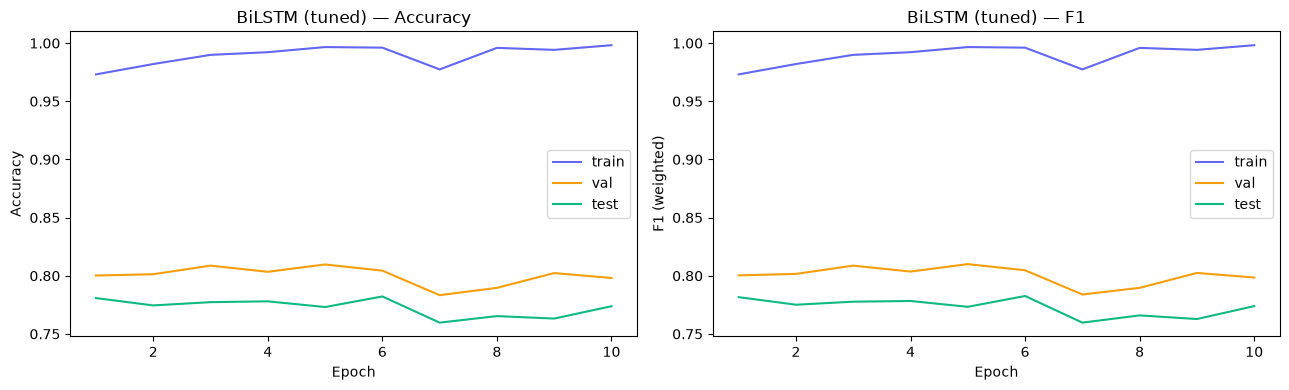

In [12]:
tuned_model = best_overall["model"]
tuned_config = best_overall["config"]
tr_loader, va_loader, te_loader = best_overall["train_loader"], best_overall["val_loader"], best_overall["test_loader"]

FINAL_EPOCHS = 20
FINAL_PATIENCE = 5
FINAL_LR = tuned_config["learning_rate"] * 0.5

optimizer = torch.optim.Adam(tuned_model.parameters(), lr=FINAL_LR, weight_decay=tuned_config["weight_decay"])
criterion = nn.CrossEntropyLoss(weight=class_weights)

best_val_f1 = best_overall["val_f1"]
best_state = {k: v.detach().cpu().clone() for k, v in tuned_model.state_dict().items()}
epochs_no_improve = 0
history = []

print(f"{'Epoch':>6} | {'train_acc':>9} {'train_f1':>9} | {'val_acc':>9} {'val_f1':>9} | {'test_acc':>9} {'test_f1':>9}")
print("-" * 76)
start = time.time()
for epoch in range(1, FINAL_EPOCHS + 1):
    train_one_epoch(tuned_model, tr_loader, optimizer, criterion)

    _, train_metrics, _, _ = evaluate(tuned_model, tr_loader, criterion)
    _, val_metrics, _, _ = evaluate(tuned_model, va_loader, criterion)
    _, test_metrics_ep, _, _ = evaluate(tuned_model, te_loader, criterion)
    history.append({
        "epoch": epoch, "train_acc": train_metrics["accuracy"], "train_f1": train_metrics["f1_weighted"],
        "val_acc": val_metrics["accuracy"], "val_f1": val_metrics["f1_weighted"],
        "test_acc": test_metrics_ep["accuracy"], "test_f1": test_metrics_ep["f1_weighted"],
    })

    print(f"{epoch:>6} | {train_metrics['accuracy']:>9.4f} {train_metrics['f1_weighted']:>9.4f} | "
          f"{val_metrics['accuracy']:>9.4f} {val_metrics['f1_weighted']:>9.4f} | "
          f"{test_metrics_ep['accuracy']:>9.4f} {test_metrics_ep['f1_weighted']:>9.4f}")

    if val_metrics["f1_weighted"] > best_val_f1:
        best_val_f1 = val_metrics["f1_weighted"]
        best_state = {k: v.detach().cpu().clone() for k, v in tuned_model.state_dict().items()}
        epochs_no_improve = 0
    else:
        epochs_no_improve += 1
        if epochs_no_improve >= FINAL_PATIENCE:
            print(f"\nEarly stopping at epoch {epoch} (best val_f1={best_val_f1:.4f})")
            break

tuned_train_time = time.time() - start
tuned_model.load_state_dict(best_state)
history_df = pd.DataFrame(history)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(history_df["epoch"], history_df["train_acc"], label="train", color="#6366f1")
axes[0].plot(history_df["epoch"], history_df["val_acc"], label="val", color="#f59e0b")
axes[0].plot(history_df["epoch"], history_df["test_acc"], label="test", color="#10b981")
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Accuracy"); axes[0].set_title(f"{MODEL_NAME} (tuned) — Accuracy"); axes[0].legend()

axes[1].plot(history_df["epoch"], history_df["train_f1"], label="train", color="#6366f1")
axes[1].plot(history_df["epoch"], history_df["val_f1"], label="val", color="#f59e0b")
axes[1].plot(history_df["epoch"], history_df["test_f1"], label="test", color="#10b981")
axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("F1 (weighted)"); axes[1].set_title(f"{MODEL_NAME} (tuned) — F1"); axes[1].legend()

plt.tight_layout()
plt.savefig(f"{RESULTS_DIR}/training_curve_{MODEL_NAME.lower()}_tuned.png", dpi=120, bbox_inches="tight")
plt.show()

In [13]:
# ── final test evaluation with the best checkpoint, and the 90% verdict ──
_, tuned_test_metrics, tuned_test_preds, tuned_test_labels = evaluate(tuned_model, te_loader, criterion)

print(f"{'Model':<24} {'F1 (weighted)':>14} {'Accuracy':>10}")
print("-" * 50)
print(f"{'Baseline (guessed)':<24} {test_metrics['f1_weighted']:>14.4f} {test_metrics['accuracy']:>10.4f}")
print(f"{'Tuned (HPT + full train)':<24} {tuned_test_metrics['f1_weighted']:>14.4f} {tuned_test_metrics['accuracy']:>10.4f}")

final_model, final_variant, final_test_metrics = tuned_model, "HPT_tuned", tuned_test_metrics
n_params = count_parameters(final_model)

print(f"\nFinal model: {MODEL_NAME} ({final_variant})")
print(f"Test accuracy: {final_test_metrics['accuracy']:.4f}  |  Test F1: {final_test_metrics['f1_weighted']:.4f}")
if final_test_metrics["accuracy"] >= 0.90 and final_test_metrics["f1_weighted"] >= 0.90:
    print("\n>>> 90%+ ACHIEVED on both accuracy and F1.")
else:
    print(f"\n>>> Did NOT reach 90%. Best so far: {max(final_test_metrics['accuracy'], test_metrics['accuracy'])*100:.1f}% accuracy.")

print(classification_report(tuned_test_labels, tuned_test_preds, target_names=["positive", "neutral", "negative"]))

mlflow.set_experiment(MLFLOW_EXPERIMENT)
mlflow.start_run(run_name=f"{MODEL_NAME}_HPT_tuned")
mlflow.log_params({**tuned_config, "final_lr": FINAL_LR})
for k, v in final_test_metrics.items():
    mlflow.log_metric(f"test_{k}", v)
mlflow.log_metric("train_time_seconds", round(tuned_train_time, 2))
mlflow.log_metric("param_count", n_params)
tuned_cm_path = save_confusion_matrix(tuned_test_labels, tuned_test_preds, f"{MODEL_NAME}_tuned")
mlflow.log_artifact(tuned_cm_path)

Model                     F1 (weighted)   Accuracy
--------------------------------------------------
Baseline (guessed)               0.4842     0.5102
Tuned (HPT + full train)         0.7733     0.7731

Final model: BiLSTM (HPT_tuned)
Test accuracy: 0.7731  |  Test F1: 0.7733

>>> Did NOT reach 90%. Best so far: 77.3% accuracy.
              precision    recall  f1-score   support

    positive       0.81      0.76      0.78       503
     neutral       0.74      0.77      0.76       511
    negative       0.78      0.79      0.78       405

    accuracy                           0.77      1419
   macro avg       0.77      0.77      0.77      1419
weighted avg       0.77      0.77      0.77      1419



## 10. Save model + tokenizer for local download

In [14]:
# ── save model + tokenizer for local download ────────────────────
tuned_model_config = {
    "vocab_size": tokenizer.vocab_size_actual,
    "embed_dim": int(tuned_config["embed_dim"]),
    "hidden_dim": int(tuned_config["hidden_dim"]),
    "num_layers": int(tuned_config["num_layers"]),
    "num_classes": NUM_LABELS,
    "dropout": float(tuned_config["dropout"]),
}

model_path = os.path.join(MODELS_DIR, "bilstm.pt")
torch.save({
    "model_state_dict": final_model.state_dict(),
    "config": tuned_model_config,
    "test_metrics": final_test_metrics,
    "variant": final_variant,
}, model_path)

tok_path = os.path.join(MODELS_DIR, "tokenizer.pkl")
with open(tok_path, "wb") as f:
    pickle.dump(tokenizer, f)

mlflow.log_artifact(model_path)
mlflow.end_run()

print(f"\nSaved model to: {model_path}")
print(f"Saved tokenizer to: {tok_path}")
print(f"\nDownload these from the Kaggle notebook's Output tab before your session ends:")
print(f"  - {MODELS_DIR}/  (trained model + tokenizer)")
print(f"  - {RESULTS_DIR}/  (confusion matrix, report, training curves)")
print(f"  - {os.path.join(BASE_DIR, 'mlflow.db')}  (all MLflow metrics/params — NOT just the mlruns/ folder!)")
print(f"  - {os.path.join(BASE_DIR, 'mlruns')}/  (MLflow artifacts)")


Saved model to: ./saved_models/bilstm.pt
Saved tokenizer to: ./saved_models/tokenizer.pkl

Download these from the Kaggle notebook's Output tab before your session ends:
  - ./saved_models/  (trained model + tokenizer)
  - ./results/  (confusion matrix, report, training curves)
  - ./mlflow.db  (all MLflow metrics/params — NOT just the mlruns/ folder!)
  - ./mlruns/  (MLflow artifacts)
